ANALISIS GENERAL DE LA SITUACION DE LAS EMPRESAS 

In [4]:
import pandas as pd
import missingno as msno
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

In [ ]:

df = pd.read_csv("Data/ratios.csv")

In [6]:
df.head()

,index,Nombre,País,Ultimo año disponible,Forma jurídica,Provincia,Localidad,Fecha constitución,Código primario CNAE 2009,Literal código CNAE 2009 primario,...,RATIO DE INTANGIBILIDAD,RATIO DE ENDEUDAMIENTO DEL EBITDA,RATIO DE ENDEUDAMIENTO SOBRE EL EBIT,COSTE MEDIO DE LA DEUDA,DSRC (Deuda Servicio Ratio de Cobertura),Margen bruto sobre ventas,Margen sobre EBITDA,ROA,ROE,CONVERSION DE EFECTIVO
0,0,"VIDRALA, SA",ESPANA,2024-12-31,Sociedad anonima,Alava,LAUDIO/LLODIO,1965-03-17 00:00:00,2313,Fabricación de vidrio hueco,...,0.005124,0.064373,0.066461,2.787798,5.572280,0.440843,0.119678,6.556690,17.199651,127.788775
1,1,AERNNOVA AEROSPACE SA,ESPANA,2024-12-31,Sociedad anonima,Alava,VITORIA-GASTEIZ,1999-07-19 00:00:00,3030,Construcción aeronáutica y espacial y su maqui...,...,0.019207,0.902495,0.951618,1.286395,0.861352,0.345646,0.122189,5.163206,9.945058,7.206189
2,3,COMPAÑIA DE BEBIDAS PEPSICO SL,ESPANA,2024-12-31,Sociedad limitada,Alava,VITORIA-GASTEIZ,1957-09-04 00:00:00,1107,Fabricación de bebidas no alcohólicas; producc...,...,0.000048,0.115917,0.128007,4.850544,1.778531,0.486891,0.202264,4.786044,69.840916,164.617050
3,4,ARRAIA-OIL SL,ESPANA,2024-12-31,Sociedad limitada,Alava,VITORIA-GASTEIZ,2001-01-21 00:00:00,4730,Comercio al por menor de combustible para la a...,...,0.040347,0.000000,0.000000,0.042608,20.929936,0.032934,0.019003,8.585769,11.736653,33.534881
4,6,"TUBOS REUNIDOS GROUP, S.L.",ESPANA,2024-12-31,Sociedad limitada,Alava,AMURRIO,2010-01-04 00:00:00,2420,"Fabricación de tubos, tuberías, perfiles hueco...",...,0.008425,0.259535,1.241911,3.898026,0.988460,0.956592,0.063892,1.100356,-6.119269,238.077372


In [7]:
df.columns

Index(['index', 'Nombre', 'País', 'Ultimo año disponible', 'Forma jurídica',
       'Provincia', 'Localidad', 'Fecha constitución',
       'Código primario CNAE 2009', 'Literal código CNAE 2009 primario',
       'Existencias\nmil EUR\nÚlt. año disp.',
       'Inmovilizado\nmil EUR\nÚlt. año disp.',
       'Inmovilizado inmaterial\nmil EUR\nÚlt. año disp.',
       'Inmovilizado material\nmil EUR\nÚlt. año disp.',
       'Otros activos fijos\nmil EUR\nÚlt. año disp.',
       'Activo circulante\nmil EUR\nÚlt. año disp.',
       'Acreedores a L. P.\nmil EUR\nÚlt. año disp.',
       'Deudores\nmil EUR\nÚlt. año disp.',
       'Otros activos líquidos\nmil EUR\nÚlt. año disp.',
       'Tesorería\nmil EUR\nÚlt. año disp.',
       'Total activo\nmil EUR\nÚlt. año disp.',
       'Fondos propios\nmil EUR\nÚlt. año disp.',
       'Capital suscrito\nmil EUR\nÚlt. año disp.',
       'Otros fondos propios\nmil EUR\nÚlt. año disp.',
       'Pasivo fijo\nmil EUR\nÚlt. año disp.',
       'Otros pasivos 

In [8]:
ratios= ['RATIO DE PRUEBA ACIDA',
    'RATIO DE LIQUIDEZ',
    'RATIO DE SOLVENCIA',
    'RATIO DE ENDEUDAMIENTO DEL EBITDA',
    'RATIO DE ENDEUDAMIENTO SOBRE EL EBIT',
    'DSRC (Deuda Servicio Ratio de Cobertura)',
    'ROA',
    'ROE',
]

df.dtypes

index                          int64
Nombre                           str
País                             str
Ultimo año disponible            str
Forma jurídica                   str
                              ...   
Margen bruto sobre ventas    float64
Margen sobre EBITDA          float64
ROA                          float64
ROE                          float64
CONVERSION DE EFECTIVO       float64
Length: 71, dtype: object

In [9]:
df["Provincia"].value_counts()

Provincia
Vizcaya      12890
Guipuzcoa     9510
Alava         4179
Name: count, dtype: int64

In [10]:
df['Código primario CNAE 2009'].value_counts()

Código primario CNAE 2009
6820    1950
5610     810
4121     626
6920     620
4941     619
        ... 
8430       1
9103       1
7731       1
322        1
5223       1
Name: count, Length: 558, dtype: int64

In [11]:
df[ratios].mean()

RATIO DE PRUEBA ACIDA                         121.437113
RATIO DE LIQUIDEZ                             119.844668
RATIO DE SOLVENCIA                             31.756141
RATIO DE ENDEUDAMIENTO DEL EBITDA               1.902524
RATIO DE ENDEUDAMIENTO SOBRE EL EBIT        -4094.905973
DSRC (Deuda Servicio Ratio de Cobertura)    19553.599942
ROA                                          -364.918691
ROE                                             9.956970
dtype: float64

In [12]:
df[ratios].describe()

,RATIO DE PRUEBA ACIDA,RATIO DE LIQUIDEZ,RATIO DE SOLVENCIA,RATIO DE ENDEUDAMIENTO DEL EBITDA,RATIO DE ENDEUDAMIENTO SOBRE EL EBIT,DSRC (Deuda Servicio Ratio de Cobertura),ROA,ROE
count,2.657900e+04,2.657900e+04,26579.000000,26579.000000,2.657900e+04,2.657900e+04,2.657900e+04,26579.000000
mean,1.214371e+02,1.198447e+02,31.756141,1.902524,-4.094906e+03,1.955360e+04,-3.649187e+02,9.956970
std,1.338219e+04,1.329638e+04,5529.622102,312.345068,1.375101e+06,9.965663e+05,6.050781e+04,741.621086
min,-2.063642e+02,0.000000e+00,-187033.828479,-11258.920478,-2.045242e+08,-1.641841e+07,-9.864600e+06,-46865.458167
25%,1.070639e+00,1.291208e+00,1.409263,0.000000,0.000000e+00,5.907338e+00,1.416176e+00,2.600290
50%,2.092499e+00,2.201357e+00,2.228090,0.002983,3.108264e-03,1.254228e+01,4.993722e+00,9.056529
75%,3.740323e+00,3.501220e+00,3.924336,0.288794,3.815648e-01,2.831831e+01,1.208072e+01,21.102219
max,2.167302e+06,2.151948e+06,881780.586468,47936.744563,9.171325e+07,1.182749e+08,5.824804e+03,72125.000000


In [13]:
df[ratios].median()

RATIO DE PRUEBA ACIDA                        2.092499
RATIO DE LIQUIDEZ                            2.201357
RATIO DE SOLVENCIA                           2.228090
RATIO DE ENDEUDAMIENTO DEL EBITDA            0.002983
RATIO DE ENDEUDAMIENTO SOBRE EL EBIT         0.003108
DSRC (Deuda Servicio Ratio de Cobertura)    12.542284
ROA                                          4.993722
ROE                                          9.056529
dtype: float64

In [14]:
df_alava = df[df["Provincia"] == "Alava"]

In [15]:
df_alava[ratios].mean()

RATIO DE PRUEBA ACIDA                         549.216121
RATIO DE LIQUIDEZ                             543.291154
RATIO DE SOLVENCIA                              6.137653
RATIO DE ENDEUDAMIENTO DEL EBITDA              -1.488261
RATIO DE ENDEUDAMIENTO SOBRE EL EBIT           -0.853360
DSRC (Deuda Servicio Ratio de Cobertura)    23394.020046
ROA                                             0.799910
ROE                                            -5.101796
dtype: float64

In [16]:
df_alava[ratios].describe()

,RATIO DE PRUEBA ACIDA,RATIO DE LIQUIDEZ,RATIO DE SOLVENCIA,RATIO DE ENDEUDAMIENTO DEL EBITDA,RATIO DE ENDEUDAMIENTO SOBRE EL EBIT,DSRC (Deuda Servicio Ratio de Cobertura),ROA,ROE
count,4.179000e+03,4.179000e+03,4179.000000,4.179000e+03,4.179000e+03,4.179000e+03,4179.000000,4179.000000
mean,5.492161e+02,5.432912e+02,6.137653,-1.488261e+00,-8.533595e-01,2.339402e+04,0.799910,-5.101796
std,3.353669e+04,3.329905e+04,85.578769,6.356154e+01,6.941679e+01,1.017441e+06,289.469721,860.332543
min,-6.468754e+00,0.000000e+00,-2056.618682,-2.277975e+03,-2.277975e+03,-1.641841e+07,-18203.981202,-46865.458167
25%,8.200450e-01,1.123936e+00,1.308219,0.000000e+00,0.000000e+00,4.055170e+00,0.280662,0.589185
50%,1.899709e+00,2.114505e+00,2.025404,8.517057e-10,5.134514e-16,1.244135e+01,4.680000,8.423864
75%,4.689036e+00,4.283469e+00,3.842111,3.139057e-01,3.209802e-01,3.038305e+01,12.807515,22.773901
max,2.167302e+06,2.151948e+06,3104.602093,5.847940e+02,1.581529e+03,6.017759e+07,951.789000,8012.864887


In [17]:
df_alava[ratios].median()

RATIO DE PRUEBA ACIDA                       1.899709e+00
RATIO DE LIQUIDEZ                           2.114505e+00
RATIO DE SOLVENCIA                          2.025404e+00
RATIO DE ENDEUDAMIENTO DEL EBITDA           8.517057e-10
RATIO DE ENDEUDAMIENTO SOBRE EL EBIT        5.134514e-16
DSRC (Deuda Servicio Ratio de Cobertura)    1.244135e+01
ROA                                         4.680000e+00
ROE                                         8.423864e+00
dtype: float64

In [18]:
df_alava['Código primario CNAE 2009'].value_counts()

Código primario CNAE 2009
6820    198
4121    118
4110    112
1102    109
5610    107
       ... 
2052      1
1439      1
2811      1
126       1
2814      1
Name: count, Length: 431, dtype: int64

In [19]:
df_alava.value_counts()

index  Nombre                                                País    Ultimo año disponible  Forma jurídica     Provincia  Localidad            Fecha constitución   Código primario CNAE 2009  Literal código CNAE 2009 primario                                                                Existencias\nmil EUR\nÚlt. año disp.  Inmovilizado\nmil EUR\nÚlt. año disp.  Inmovilizado inmaterial\nmil EUR\nÚlt. año disp.  Inmovilizado material\nmil EUR\nÚlt. año disp.  Otros activos fijos\nmil EUR\nÚlt. año disp.  Activo circulante\nmil EUR\nÚlt. año disp.  Acreedores a L. P.\nmil EUR\nÚlt. año disp.  Deudores\nmil EUR\nÚlt. año disp.  Otros activos líquidos\nmil EUR\nÚlt. año disp.  Tesorería\nmil EUR\nÚlt. año disp.  Total activo\nmil EUR\nÚlt. año disp.  Fondos propios\nmil EUR\nÚlt. año disp.  Capital suscrito\nmil EUR\nÚlt. año disp.  Otros fondos propios\nmil EUR\nÚlt. año disp.  Pasivo fijo\nmil EUR\nÚlt. año disp.  Otros pasivos fijos\nmil EUR\nÚlt. año disp.  Provisiones\nmil EUR\nÚlt. a

In [20]:
df_vizcaya= df[df["Provincia"] == "Vizcaya"]

In [21]:
df_vizcaya[ratios].mean()

RATIO DE PRUEBA ACIDA                          16.274409
RATIO DE LIQUIDEZ                              14.470072
RATIO DE SOLVENCIA                              4.032851
RATIO DE ENDEUDAMIENTO DEL EBITDA               0.268603
RATIO DE ENDEUDAMIENTO SOBRE EL EBIT       -15865.515395
DSRC (Deuda Servicio Ratio de Cobertura)    24441.994762
ROA                                             7.992430
ROE                                            17.626201
dtype: float64

In [22]:
df_vizcaya.value_counts()

index  Nombre                                País    Ultimo año disponible  Forma jurídica     Provincia  Localidad  Fecha constitución   Código primario CNAE 2009  Literal código CNAE 2009 primario                                                    Existencias\nmil EUR\nÚlt. año disp.  Inmovilizado\nmil EUR\nÚlt. año disp.  Inmovilizado inmaterial\nmil EUR\nÚlt. año disp.  Inmovilizado material\nmil EUR\nÚlt. año disp.  Otros activos fijos\nmil EUR\nÚlt. año disp.  Activo circulante\nmil EUR\nÚlt. año disp.  Acreedores a L. P.\nmil EUR\nÚlt. año disp.  Deudores\nmil EUR\nÚlt. año disp.  Otros activos líquidos\nmil EUR\nÚlt. año disp.  Tesorería\nmil EUR\nÚlt. año disp.  Total activo\nmil EUR\nÚlt. año disp.  Fondos propios\nmil EUR\nÚlt. año disp.  Capital suscrito\nmil EUR\nÚlt. año disp.  Otros fondos propios\nmil EUR\nÚlt. año disp.  Pasivo fijo\nmil EUR\nÚlt. año disp.  Otros pasivos fijos\nmil EUR\nÚlt. año disp.  Provisiones\nmil EUR\nÚlt. año disp.  Pasivo líquido\nmil EUR\nÚlt

In [23]:
df_vizcaya[ratios].describe()

,RATIO DE PRUEBA ACIDA,RATIO DE LIQUIDEZ,RATIO DE SOLVENCIA,RATIO DE ENDEUDAMIENTO DEL EBITDA,RATIO DE ENDEUDAMIENTO SOBRE EL EBIT,DSRC (Deuda Servicio Ratio de Cobertura),ROA,ROE
count,12890.000000,12890.000000,12890.000000,1.289000e+04,1.289000e+04,1.289000e+04,12890.000000,12890.000000
mean,16.274409,14.470072,4.032851,2.686033e-01,-1.586552e+04,2.444199e+04,7.992430,17.626201
std,849.689719,650.839321,21.423272,1.959523e+01,1.801434e+06,1.259989e+06,28.824026,686.076819
min,-15.469874,0.000000,-1619.572246,-1.379330e+03,-2.045242e+08,-6.225390e+06,-1353.288817,-14275.854304
25%,1.265930,1.422098,1.558570,4.283375e-18,0.000000e+00,7.201073e+00,2.650123,4.589295
50%,2.183404,2.228270,2.419253,3.850045e-02,4.199584e-02,1.254228e+01,5.030875,9.140622
75%,3.380167,2.937200,3.924336,3.135236e-01,4.662273e-01,2.219279e+01,10.945833,18.754077
max,70994.549550,52840.835736,705.464112,8.895277e+02,1.192223e+03,1.182749e+08,1244.948573,72125.000000


In [24]:
df_vizcaya[ratios].median()

RATIO DE PRUEBA ACIDA                        2.183404
RATIO DE LIQUIDEZ                            2.228270
RATIO DE SOLVENCIA                           2.419253
RATIO DE ENDEUDAMIENTO DEL EBITDA            0.038500
RATIO DE ENDEUDAMIENTO SOBRE EL EBIT         0.041996
DSRC (Deuda Servicio Ratio de Cobertura)    12.542284
ROA                                          5.030875
ROE                                          9.140622
dtype: float64

In [25]:
df_vizcaya['Código primario CNAE 2009'].value_counts()

Código primario CNAE 2009
6820    1036
5610     389
4941     330
6920     310
7112     293
        ... 
2752       1
899        1
1820       1
9106       1
2896       1
Name: count, Length: 499, dtype: int64

In [26]:
df_Guipuzcoa= df[df["Provincia"] == "Guipuzcoa"]

In [27]:
df_Guipuzcoa[ratios].mean()

RATIO DE PRUEBA ACIDA                          75.996396
RATIO DE LIQUIDEZ                              76.595002
RATIO DE SOLVENCIA                             80.590302
RATIO DE ENDEUDAMIENTO DEL EBITDA               5.607186
RATIO DE ENDEUDAMIENTO SOBRE EL EBIT        10060.100291
DSRC (Deuda Servicio Ratio de Cobertura)    11240.190390
ROA                                         -1031.076671
ROE                                             6.179285
dtype: float64

In [28]:
df_Guipuzcoa.value_counts()

index  Nombre                                          País    Ultimo año disponible  Forma jurídica     Provincia  Localidad               Fecha constitución   Código primario CNAE 2009  Literal código CNAE 2009 primario                                                                                        Existencias\nmil EUR\nÚlt. año disp.  Inmovilizado\nmil EUR\nÚlt. año disp.  Inmovilizado inmaterial\nmil EUR\nÚlt. año disp.  Inmovilizado material\nmil EUR\nÚlt. año disp.  Otros activos fijos\nmil EUR\nÚlt. año disp.  Activo circulante\nmil EUR\nÚlt. año disp.  Acreedores a L. P.\nmil EUR\nÚlt. año disp.  Deudores\nmil EUR\nÚlt. año disp.  Otros activos líquidos\nmil EUR\nÚlt. año disp.  Tesorería\nmil EUR\nÚlt. año disp.  Total activo\nmil EUR\nÚlt. año disp.  Fondos propios\nmil EUR\nÚlt. año disp.  Capital suscrito\nmil EUR\nÚlt. año disp.  Otros fondos propios\nmil EUR\nÚlt. año disp.  Pasivo fijo\nmil EUR\nÚlt. año disp.  Otros pasivos fijos\nmil EUR\nÚlt. año disp.  Provisi

In [29]:
df_Guipuzcoa[ratios].describe()

,RATIO DE PRUEBA ACIDA,RATIO DE LIQUIDEZ,RATIO DE SOLVENCIA,RATIO DE ENDEUDAMIENTO DEL EBITDA,RATIO DE ENDEUDAMIENTO SOBRE EL EBIT,DSRC (Deuda Servicio Ratio de Cobertura),ROA,ROE
count,9510.000000,9510.000000,9510.000000,9.510000e+03,9.510000e+03,9.510000e+03,9.510000e+03,9510.000000
mean,75.996396,76.595002,80.590302,5.607186e+00,1.006010e+04,1.124019e+04,-1.031077e+03,6.179285
std,2302.170408,2507.227620,9244.213767,5.199656e+02,9.413195e+05,4.111625e+05,1.011555e+05,757.532922
min,-206.364183,0.000000,-187033.828479,-1.125892e+04,-2.972911e+04,-5.182199e+06,-9.864600e+06,-30713.168279
25%,0.923232,1.190638,1.310458,0.000000e+00,0.000000e+00,4.869184e+00,3.892552e-01,0.920537
50%,2.040242,2.146635,2.039184,5.945306e-16,1.784504e-16,1.254228e+01,5.115949e+00,8.603104
75%,4.886894,4.476333,3.825614,2.242734e-01,2.316908e-01,3.251066e+01,1.328853e+01,22.969356
max,170778.312118,185743.213935,881780.586468,4.793674e+04,9.171325e+07,2.939060e+07,5.824804e+03,32949.680715


In [30]:
df_Guipuzcoa[ratios].median()

RATIO DE PRUEBA ACIDA                       2.040242e+00
RATIO DE LIQUIDEZ                           2.146635e+00
RATIO DE SOLVENCIA                          2.039184e+00
RATIO DE ENDEUDAMIENTO DEL EBITDA           5.945306e-16
RATIO DE ENDEUDAMIENTO SOBRE EL EBIT        1.784504e-16
DSRC (Deuda Servicio Ratio de Cobertura)    1.254228e+01
ROA                                         5.115949e+00
ROE                                         8.603104e+00
dtype: float64

In [31]:
df_Guipuzcoa['Código primario CNAE 2009'].value_counts()

Código primario CNAE 2009
6820    716
5610    314
4110    253
4121    218
4941    212
       ... 
5223      1
3213      1
5829      1
7220      1
6419      1
Name: count, Length: 484, dtype: int64

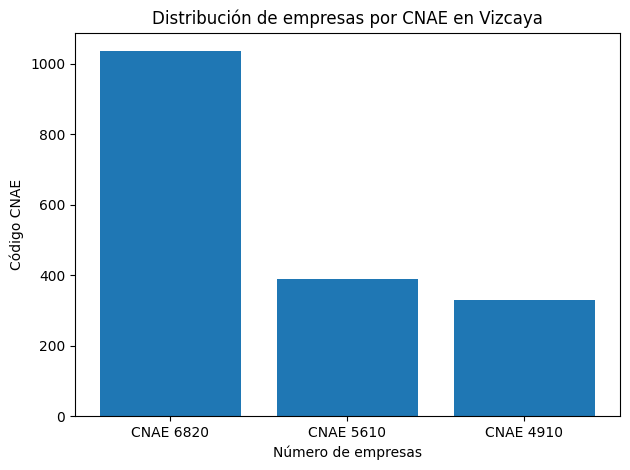

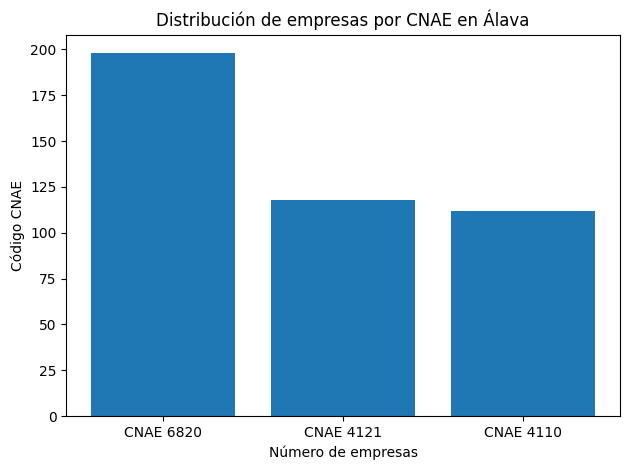

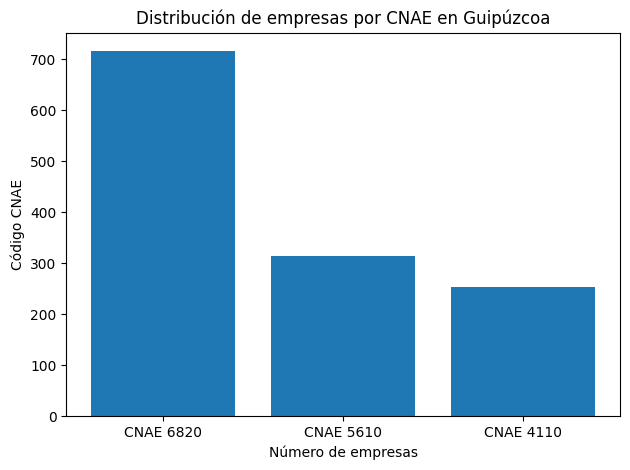

In [36]:
import matplotlib.pyplot as plt

# Datos por provincia (número de empresas por CNAE)
vizcaya = {
    'CNAE 6820': 1036,  # Alquiler de bienes inmobiliarios por cuenta propia
    'CNAE 5610': 389,   # Restaurantes y puestos de comidas
    'CNAE 4910': 330    # Transporte interurbano de pasajeros por ferrocarril
}

alava = {
    'CNAE 6820': 198,   # Alquiler de bienes inmobiliarios por cuenta propia
    'CNAE 4121': 118,   # Construcción de edificios residenciales
    'CNAE 4110': 112    # Promoción inmobiliaria
}

guipuzcoa = {
    'CNAE 6820': 716,   # Alquiler de bienes inmobiliarios por cuenta propia
    'CNAE 5610': 314,   # Restaurantes y puestos de comidas
    'CNAE 4110': 253    # Promoción inmobiliaria
}

provincias = {
    'Vizcaya': vizcaya,
    'Álava': alava,
    'Guipúzcoa': guipuzcoa
}

# Crear un gráfico de barras por provincia
for provincia, datos in provincias.items():
    plt.figure()
    plt.bar(datos.keys(), datos.values())
    plt.title(f'Distribución de empresas por CNAE en {provincia}')

    plt.xlabel('Número de empresas')
    plt.ylabel('Código CNAE')

    plt.tight_layout()
    plt.show()